<a href="https://colab.research.google.com/github/naubergois/curso-segmentacao-colab/blob/main/notebooks/05-tomografia.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 5. Tomografia

Uma tomografia não é uma foto de quarto. É uma pilha de cortes. Em cada corte, o número do pixel é densidade: osso claro, ar escuro, músculo no meio. A unidade usual é Hounsfield. Água fica perto de zero. Pulmão, bem abaixo. Osso, bem acima.

A máscara daqui não vem das 80 classes. Ela sai da densidade. O ar de fora do corpo não entra. Entra o ar que está dentro do tórax.

O volume é o CTChest, amostra pública do 3D Slicer. Tem uns 40 MB.

> No Colab: **Ambiente de execução → Executar tudo**. CPU chega.

In [1]:
!pip install -q pynrrd

In [2]:
import base64
import subprocess
import urllib.request
from pathlib import Path

from IPython.display import HTML, display


def baixar(url, destino):
    if not Path(destino).exists():
        urllib.request.urlretrieve(url, destino)
    print(f"{destino}: {Path(destino).stat().st_size / 1e6:.1f} MB")
    return destino


def mascaras_originais(resultado):
    """Máscaras no tamanho da foto, como array booleano (n, altura, largura).

    A rede responde numa grade menor que a imagem. Aqui a máscara é esticada
    de volta ao tamanho original, para a área bater com os pixels da foto.
    """
    import cv2
    import numpy as np

    altura, largura = resultado.orig_shape
    if resultado.masks is None or len(resultado.masks) == 0:
        return np.zeros((0, altura, largura), dtype=bool)
    saida = []
    for mascara in resultado.masks.data.cpu().numpy():
        mascara = cv2.resize(mascara, (largura, altura), interpolation=cv2.INTER_NEAREST)
        saida.append(mascara > 0.5)
    return np.stack(saida)


def mostrar_video(caminho, largura=720):
    """Converte para H.264 (o navegador não toca mp4v) e embute no notebook."""
    web = str(Path(caminho).with_suffix("")) + "_web.mp4"
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", caminho,
         "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", web],
        check=True,
    )
    dados = base64.b64encode(Path(web).read_bytes()).decode()
    display(HTML(f'<video width="{largura}" controls autoplay muted loop>'
                 f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))
    return web


def baixar_para_maquina(caminho):
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print(f"Fora do Colab: o arquivo está em {Path(caminho).resolve()}")

In [3]:
import nrrd
import numpy as np
from scipy import ndimage
import matplotlib.pyplot as plt

arquivo = baixar("https://github.com/Slicer/SlicerTestingData/releases/download/SHA256/4507b664690840abb6cb9af2d919377ffc4ef75b167cb6fd0f747befdb12e38e", "ct-torax.nrrd")
volume, _cabecalho = nrrd.read(arquivo)
volume = volume.astype(np.float32)
print(f"{volume.shape[0]} x {volume.shape[1]} x {volume.shape[2]} cortes")
print(f"densidade de {volume.min():.0f} a {volume.max():.0f}")
assert volume.ndim == 3

ct-torax.nrrd: 42.2 MB


512 x 512 x 139 cortes
densidade de -3024 a 3071


## O corte com mais pulmão

Pulmão, neste número, é o que fica entre −950 e −400. O corte que mais tem desses pixels é o que a gente olha primeiro.

In [4]:
def pixels_de_pulmao(fatia):
    return int(((fatia > -950) & (fatia < -400)).sum())

areas = [pixels_de_pulmao(volume[:, :, z]) for z in range(volume.shape[2])]
z = int(np.argmax(areas))
fatia = volume[:, :, z]
print(f"corte {z}, {areas[z]} pixels na faixa do pulmão")

corte 102, 90263 pixels na faixa do pulmão


## A janela

O olho não lê −1000 e 3000 ao mesmo tempo. A janela de pulmão espalha os cinzas em volta de −600. Osso estoura no branco. Ar de fora fica preto.

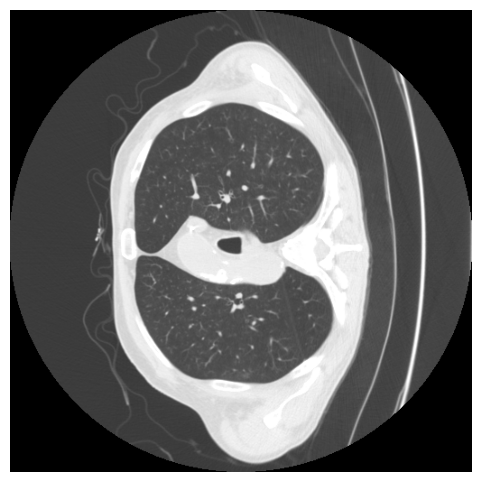

In [5]:
def janela(img, centro, largura):
    baixo = centro - largura / 2
    alto = centro + largura / 2
    return np.clip((img - baixo) / (alto - baixo), 0, 1)

plt.figure(figsize=(6, 6))
plt.imshow(janela(fatia, -600, 1500), cmap="gray")
plt.axis("off")
plt.show()

## A máscara do pulmão

Primeiro o corpo: tudo mais denso que −300, com os buracos preenchidos. O pulmão é o buraco que voltou a ser ar, dentro desse corpo. O que encosta na borda da imagem é ar de fora, e sai.

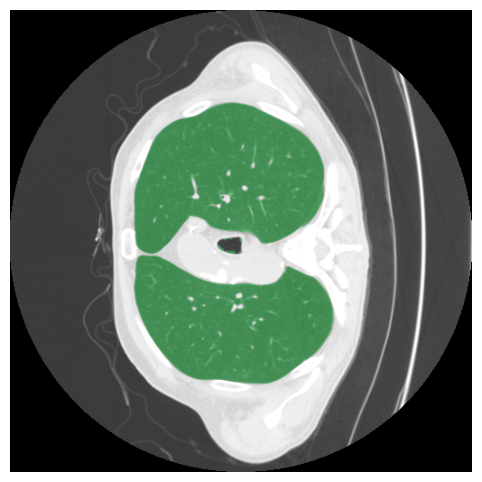

o pulmão cobre 17.9% deste corte


In [6]:
def mascara_pulmao(fatia):
    corpo = ndimage.binary_fill_holes(fatia > -300)
    pulmao = corpo & (fatia > -950) & (fatia < -400)
    pulmao = ndimage.binary_opening(pulmao, iterations=1)
    rotulo, n = ndimage.label(pulmao)
    borda = set(rotulo[0, :]) | set(rotulo[-1, :]) | set(rotulo[:, 0]) | set(rotulo[:, -1])
    borda.discard(0)
    for pedaco in borda:
        pulmao[rotulo == pedaco] = False
    return pulmao

pulmao = mascara_pulmao(fatia)
cor = plt.cm.gray(janela(fatia, -600, 1500))[..., :3]
cor[pulmao] = 0.55 * cor[pulmao] + 0.45 * np.array([0.2, 0.85, 0.35])
plt.figure(figsize=(6, 6))
plt.imshow(cor)
plt.axis("off")
plt.show()
print(f"o pulmão cobre {pulmao.mean() * 100:.1f}% deste corte")

## O osso no mesmo corte

Osso é o que passa de 300. A máscara é fina: vértebra, costela, escápula. Vaso e brônquio continuam de fora das duas máscaras, porque não são ar nem osso.

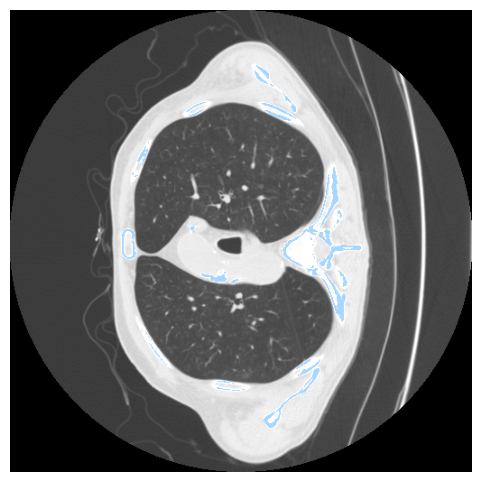

osso: 2968 pixels


In [7]:
osso = fatia > 300
cor = plt.cm.gray(janela(fatia, -600, 1500))[..., :3]
cor[osso] = 0.55 * cor[osso] + 0.45 * np.array([0.25, 0.65, 1.0])
plt.figure(figsize=(6, 6))
plt.imshow(cor)
plt.axis("off")
plt.show()
print(f"osso: {int(osso.sum())} pixels")

## Três alturas

O pulmão não tem o mesmo tamanho no alto e na base. Três cortes, com a mesma máscara, mostram a mudança.

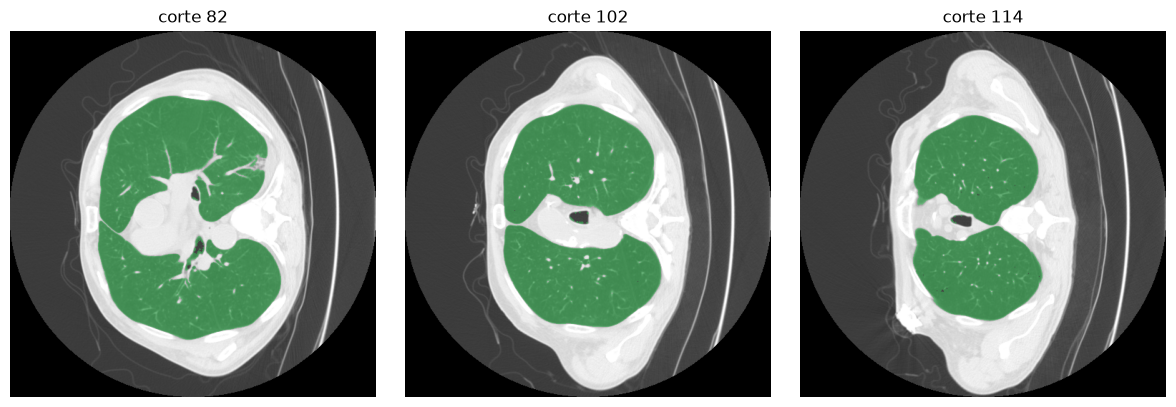

In [8]:
escolhidos = [z for z in (z - 20, z, z + 12) if 0 <= z < volume.shape[2]]
fig, eixos = plt.subplots(1, len(escolhidos), figsize=(12, 4))
for eixo, indice in zip(eixos, escolhidos):
    f = volume[:, :, indice]
    m = mascara_pulmao(f)
    img = plt.cm.gray(janela(f, -600, 1500))[..., :3]
    img[m] = 0.55 * img[m] + 0.45 * np.array([0.2, 0.85, 0.35])
    eixo.imshow(img)
    eixo.set_title(f"corte {indice}")
    eixo.axis("off")
plt.tight_layout()
plt.show()

## O que fica

A máscara do pulmão é uma conta de densidade. Vaso dentro do pulmão fica de fora, porque é tecido. Isso ainda não é um laudo, e não marca nódulo: um nódulo tem densidade de tecido e some no meio da máscara, ou nem entra nela.

O modelo das aulas 1 a 4 não lê este arquivo. Ele não tem classe para pulmão.